Створимо модель класифікації зображень кота/собаки та демонстрацію Gradio, для завантаження зображення для прогнозування класу. Модель буде згортковою нейронною мережею CNN, яка тренуватиметься на зображеннях котів і собак як об’єктів і назв їх класів як міток.
Імпортуємо необхідні бібілотеки

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import os
import cv2

from sklearn.model_selection import train_test_split
from sklearn import metrics

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D

import gradio
import gradio as gr

Переглядаємо наші дані. Зображення кота/собаки взято з джерела
набору даних, опублікованого в TensorFlow datasets.
Перевіримо перше зображення кота.

In [ ]:
import os
import shutil
import tensorflow as tf
import tensorflow_datasets as tfds

# 1. Завантажуємо датасет через TFDS (надійно, без 403)
dataset, info = tfds.load(
    "cats_vs_dogs",
    split="train",
    with_info=True,
    as_supervised=True
)

# 2. Створюємо структуру папок
os.makedirs("PetImages/Cat", exist_ok=True)
os.makedirs("PetImages/Dog", exist_ok=True)

# 3. Зберігаємо зображення
cat_count = 0
dog_count = 0
limit = 12000  # скільки зображень взяти

for image, label in dataset:
    img = tf.image.encode_jpeg(image)

    if label.numpy() == 0 and cat_count < limit:   # 0 = Cat
        filename = f"PetImages/Cat/cat_{cat_count}.jpg"
        tf.io.write_file(filename, img)
        cat_count += 1

    if label.numpy() == 1 and dog_count < limit:   # 1 = Dog
        filename = f"PetImages/Dog/dog_{dog_count}.jpg"
        tf.io.write_file(filename, img)
        dog_count += 1

    if cat_count >= limit and dog_count >= limit:
        break

print("Готово! Створено PetImages/Cat і PetImages/Dog")
print("Cats:", cat_count, "Dogs:", dog_count)


Готово! Створено PetImages/Cat і PetImages/Dog
Cats: 11658 Dogs: 11604


In [ ]:
category="Cat"

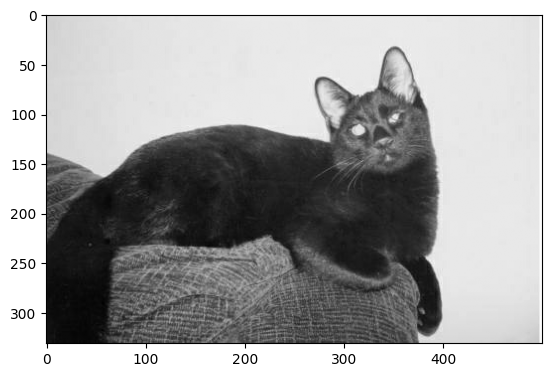

The image shape is (331, 500)


In [ ]:
DATADIR = os.path.abspath(os.getcwd()) + '/PetImages'
path = os.path.join(DATADIR, category)
first_img_path = os.listdir(path)[0]
#path to cats or dogs dir
img_array = cv2.imread(os.path.join(path, first_img_path), cv2.IMREAD_GRAYSCALE)
plt.imshow(img_array, cmap = "gray")
plt.show()
#show image shape
print('The image shape is {}'.format(img_array.shape))

In [ ]:
import random
CATEGORIES = ["Cat", "Dog"]
IMG_SIZE = 100   # або будь-який розмір, який ти вибрав

Оськыльки в нас модель CNN, ми змінимо
розмір усіх зображень на форму (100, 100) і змінимо їхні кольори на
градації сірого.

Функції та мітки також буде розділено та додано до списків X і y
відповідно

In [ ]:
# create array of data
data = []

def create_data():
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        class_num = CATEGORIES.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
                new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                data.append([new_array, class_num])  # <-- Правильний відступ!
            except Exception as e:
                pass

create_data()

# shuffle
random.shuffle(data)

# separate features and labels
X = []
y = []

for features, label in data:
    X.append(features)
    y.append(label)

# convert to numpy arrays
X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)
y = np.array(y)


приклад зображення зі зміненим розміром показано нижче

The image shape is (100, 100, 1)


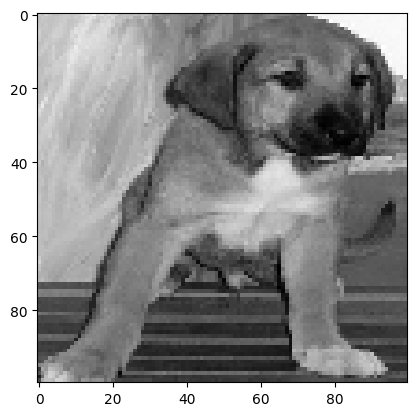

In [ ]:
#show first feature image X
first_feature = X[0]
plt.imshow(first_feature, cmap = 'gray')
print('The image shape is {}'.format(first_feature.shape))

Нормалізуємо зображення, щоб переконатися, що кожен піксель
має подібний розподіл даних (дозволяє швидше конвергенцію під
час навчання моделі згорткової нейронної мережі)

In [ ]:
#normalize images
X = X/255.0

Розділяємо дані навчання (70%) і тестування (30%). Загалом буде 16 283 навчальні та 6 979 тестові дані.

In [ ]:
#separate training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print('the shape of training features is {}'.format(X_train.shape))
print('the shape of training labels is {}'.format(y_train.shape))

print('the shape of test features is {}'.format(X_test.shape))
print('the shape of test labels is {}'.format(y_test.shape))

the shape of training features is (16283, 100, 100, 1)
the shape of training labels is (16283,)
the shape of test features is (6979, 100, 100, 1)
the shape of test labels is (6979,)


Створюємо модель згорткової нейронної мережі (CNN). Вона
складатиметься з кількох шарів згортки, шарів максимального
об’єднання та шарів вилучення. Усі функції активації в згорткових
шарах будуть relu, тоді як функція активації для вихідного щільного
шару буде softmax.

In [ ]:
#create model
model = Sequential()

model.add(Conv2D (64, (3,3), activation = 'relu'))
model.add(MaxPooling2D (2,2))
model.add(Dropout (0.1))

model.add(Conv2D (64, (3,3), activation = 'relu'))
model.add(MaxPooling2D (2,2))
model.add(Dropout (0.2))

model.add(Conv2D (64, (3,3), activation = 'relu'))
model.add(MaxPooling2D (2,2))
model.add(Dropout (0.2))

model.add(Flatten())

model.add(Dense (128, input_shape = X.shape[1:], activation = 'relu'))

#output layer
model.add(Dense (2, activation = 'softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


скомпілювати модель із такими параметрами:

In [ ]:
#compile the model
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=['accuracy'])

навчимо модель з 5 епохами та розподілом перевірки 0,1

In [ ]:
#fit model
history = model.fit(X_train, y_train, epochs=5, validation_split=0.1)

Epoch 1/5
458/458 ━━━━━━━━━━━━━━━━━━━━ 416s 901ms/step - accuracy: 0.5595 - loss: 0.6771 - val_accuracy: 0.6206 - val_loss: 0.6529
Epoch 2/5
458/458 ━━━━━━━━━━━━━━━━━━━━ 422s 859ms/step - accuracy: 0.6835 - loss: 0.5889 - val_accuracy: 0.7225 - val_loss: 0.5530
Epoch 3/5
458/458 ━━━━━━━━━━━━━━━━━━━━ 450s 877ms/step - accuracy: 0.7544 - loss: 0.5022 - val_accuracy: 0.7004 - val_loss: 0.5718
Epoch 4/5
458/458 ━━━━━━━━━━━━━━━━━━━━ 398s 869ms/step - accuracy: 0.7834 - loss: 0.4565 - val_accuracy: 0.7741 - val_loss: 0.4796
Epoch 5/5
458/458 ━━━━━━━━━━━━━━━━━━━━ 448s 883ms/step - accuracy: 0.8078 - loss: 0.4163 - val_accuracy: 0.7790 - val_loss: 0.4585


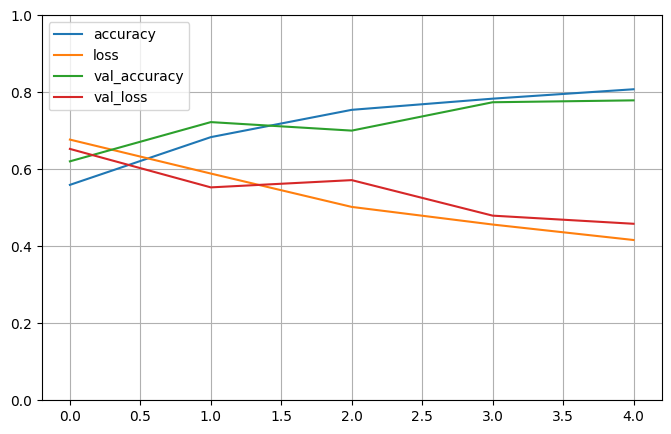

In [ ]:
#show learning curves
#mean training loss and accuracy measured over each epoch
#mean validation loss and accuracy measured at the end of each epoch
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1) # set the vertical range to [0-1]
plt.show()

Модель не перенавчається, оскільки немає значного розриву між
навчанням і точністю/втратами перевірки. Точність перевірки
трохи перевищує точність навчання, що може статися під час
використання шарів вилучення (dropout layers).

Прогнозуємо класи тестових даних і порівнюємо, наскільки цу є
точним.

In [ ]:
#use predict_classes() to find the class with the highest probability
# y_pred = model.predict_classes(X_test)
# predict_classes() більше не існує у нових версіях TensorFlow/Keras (2.6+).
# Замість цього треба використовувати model.predict()
# і обирати індекс з найбільшою ймовірністю через np.argmax.

# отримуємо ймовірності для кожного класу
y_prob = model.predict(X_test)

# перетворюємо ймовірності на індекс класу
y_pred = np.argmax(y_prob, axis=1)

print("Performance Summary of Sequential Neural Network on test data:")

#show classification report
print(metrics.classification_report(y_test, y_pred))

#show confusion matrix
print(metrics.confusion_matrix(y_test, y_pred))

219/219 ━━━━━━━━━━━━━━━━━━━━ 49s 221ms/step
Performance Summary of Sequential Neural Network on test data:
              precision    recall  f1-score   support

           0       0.84      0.78      0.80      3531
           1       0.79      0.84      0.81      3448

    accuracy                           0.81      6979
   macro avg       0.81      0.81      0.81      6979
weighted avg       0.81      0.81      0.81      6979

[[2741  790]
 [ 541 2907]]


загальна точність 80
можемо швидко знайти перші 5 правильних і неправильних
класифікацій

In [ ]:
import matplotlib.pyplot as plt

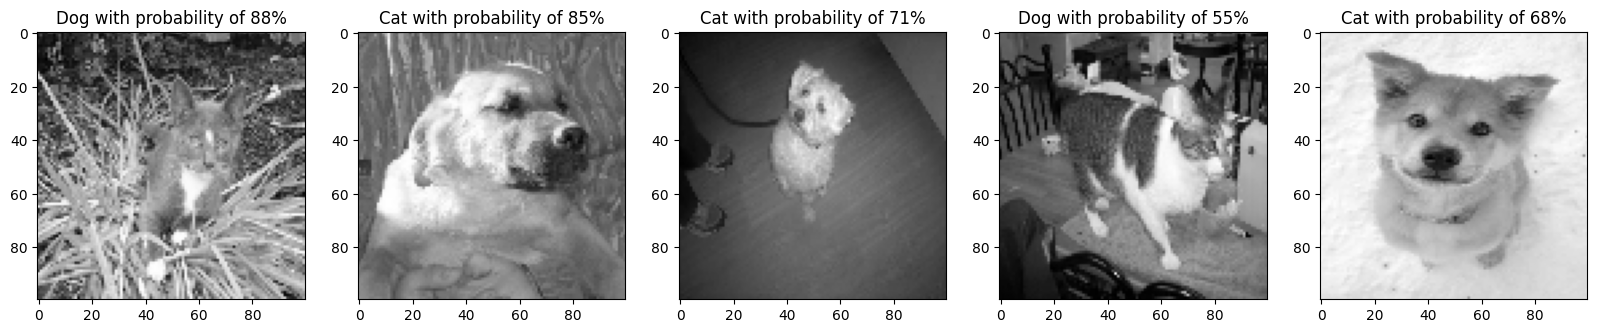

In [ ]:
# class names
class_names = ["Cat", "Dog"]

# знайти індекси неправильно передбачених зображень
incorrect_indices = [i for i in range(len(y_test)) if y_test[i] != y_pred[i]]

# показуємо перші 5
fig, ax = plt.subplots(1, 5, figsize=(20, 20))

for i, incorrect_idx in enumerate(incorrect_indices[:5]):
    ax[i].imshow(X_test[incorrect_idx].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    ax[i].set_title("{} with probability of {}%".format(
        class_names[y_pred[incorrect_idx]],
        int(max(y_prob[incorrect_idx]) * 100)
    ))


Демонстрація моделі з використанням Gradio

In [ ]:
# У нових версіях Gradio (3.x+) модулі gradio.inputs та gradio.outputs більше не використовуються.
# Тепер усе робиться через gr.Image та gr.Label.
# потрібно змінити код, щоб використовувати новий API.
import gradio as gr
import numpy as np
import cv2

In [ ]:

# функція передбачення
def cat_or_dog(img):
    # перетворюємо на чорно-біле та змінюємо розмір
    img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    img = cv2.resize(img, (100, 100))
    img = img / 255.0
    img = img.reshape(1, 100, 100, 1)

    prediction = model.predict(img)[0]
    class_names = ["Cat", "Dog"]
    return {class_names[i]: float(prediction[i]) for i in range(2)}

# створюємо інтерфейс
iface = gr.Interface(
    fn=cat_or_dog,
    inputs=gr.Image(type="numpy", label="Upload Image"),
    outputs=gr.Label(num_top_classes=2, label="Prediction")
)

iface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7ffbdf06b9fcf40b52.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


У цьому коді відбувається наступне:

1. спочатку створюємо функцію під назвою cat_or_dog(), яка
приймає масив зображень як вхідні дані, використовує
модель для прогнозування та повертає словник із назвою
кожного класу як ключем і його відповідною ймовірністю
як значенням (наприклад, {Dog: 0.6, Кішка: 0,4})
2. Налаштовуємо завантаження вхідних даних:
трансформуйте вхідне зображення відповідно до вхідної
форми, на якій навчалася модель, а це (100, 100) у нашому
випадку. Ми також встановили джерело як «завантажити»,
щоб ми могли завантажувати власні зображення в Gradio
3. Створення інтерфейсу; використовуємо функцію
cat_or_dog(), яку ми створили вище.

In [ ]:
from google.colab import files


In [ ]:
model.save("my_model.h5")

In [ ]:
files.download("my_model.h5") # зберіг модель на комп


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
uploaded = files.upload()  # відкриється вікно вибору файлу щоб зкачати модель з компа


Saving my_model.h5 to my_model.h5


In [ ]:
# Завантаження моделі у Keras
from tensorflow.keras.models import load_model

model = load_model("my_model.h5")  # назва файлу має збігатися